# Simulación de portafolios: activos independientes vs. correlacionados

**Valor inicial:** 100,000 MXN · **Horizonte:** 1 año (252 pasos) · **Simulaciones:** 10,000 · **Modelo:** Movimiento Browniano Geométrico (GBM) multiactivo

## Metodología

Para cada activo *i*:

$$S_{t+\Delta t,i} = S_{t,i}\exp\Big[(\mu_i - \tfrac12\sigma_i^2)\Delta t + \sigma_i\sqrt{\Delta t}\,\varepsilon_i\Big]$$

- **Independiente:** $\varepsilon = Z$, con $Z\sim N(0,I)$.
- **Correlacionado:** $\varepsilon = Z L^\top$, donde $L$ es la descomposición de Cholesky de la matriz de correlación $R = LL^\top$. Así $\mathrm{Corr}(\varepsilon)=R$.
- **Comparación controlada:** ambos casos usan **exactamente los mismos $Z$** (misma semilla). La diferencia entre casos se debe solo a la correlación y no al ruido de muestreo.
- **Acciones fijas (buy & hold):** si compramos $n_i = w_i V_0 / S_{0,i}$ acciones, el valor del portafolio es $V_t = V_0\sum_i w_i\,S_{t,i}/S_{0,i}$. Los precios iniciales se cancelan.

> **Supuestos importantes.** No tuve acceso a datos de mercado, así que $\mu$, $\sigma$ y $\rho$ son supuestos razonables y están en un solo lugar para que los reemplaces por los estimados con datos históricos de clase. En el ejercicio A, los 3 esquemas también son supuestos: ajústalos a los de clase.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

V0 = 100_000      # valor inicial (MXN)
T = 1.0           # horizonte (años)
STEPS = 252       # días hábiles
N = 10_000        # número de simulaciones
dt = T / STEPS
SEED = 42
C_IND, C_COR = "#1f77b4", "#d62728"   # azul = independiente, rojo = correlacionado

In [2]:
def corr_from_upper(n, upper):
    # Construye la matriz de correlación simétrica a partir del triángulo superior.
    R = np.eye(n); k = 0
    for i in range(n):
        for j in range(i + 1, n):
            R[i, j] = R[j, i] = upper[k]; k += 1
    return R

def simulate_paths(mu, sigma, R, correlated, seed=SEED):
    # GBM multiactivo. Devuelve (S_t/S_0 con forma (N, STEPS+1, n_activos), log-retornos).
    rng = np.random.default_rng(seed)           # misma semilla => mismos Z en ambos casos
    n = len(mu)
    Z = rng.standard_normal((N, STEPS, n))
    if correlated:
        L = np.linalg.cholesky(R)               # R = L L'
        Z = Z @ L.T                             # impone la correlación
    logret = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    growth = np.exp(np.cumsum(logret, axis=1))
    growth = np.concatenate([np.ones((N, 1, n)), growth], axis=1)
    return growth, logret

def portfolio_paths(growth, w):
    return V0 * (growth * np.asarray(w)).sum(axis=2)

def stats(final):
    p5 = np.percentile(final, 5)
    return {"Media": final.mean(), "Desv. est.": final.std(), "P5": p5,
            "Mediana": np.median(final), "P95": np.percentile(final, 95),
            "P(pérdida)": (final < V0).mean(),
            "VaR 95%": V0 - p5, "CVaR 95%": V0 - final[final <= p5].mean()}

def run_exercise(mu, sigma, R, schemes, labels):
    mu, sigma = np.asarray(mu, float), np.asarray(sigma, float)
    g_i, lr_i = simulate_paths(mu, sigma, R, correlated=False)
    g_c, lr_c = simulate_paths(mu, sigma, R, correlated=True)
    emp_i = np.corrcoef(lr_i.reshape(-1, len(mu)).T)    # verificación
    emp_c = np.corrcoef(lr_c.reshape(-1, len(mu)).T)
    rows, paths = [], {}
    for k, (w, lab) in enumerate(zip(schemes, labels), 1):
        vi, vc = portfolio_paths(g_i, w), portfolio_paths(g_c, w)
        paths[k] = (vi, vc)
        for caso, v in (("Independiente", vi[:, -1]), ("Correlacionado", vc[:, -1])):
            s = stats(v); s["Esquema"] = f"{k}: {lab}"; s["Caso"] = caso; rows.append(s)
    return pd.DataFrame(rows).set_index(["Esquema", "Caso"]), paths, emp_i, emp_c

def formato(df):
    out = df.copy()
    for c in out.columns:
        out[c] = out[c].map(lambda x: f"{x:.1%}") if c == "P(pérdida)" else out[c].map(lambda x: f"{x:,.0f}")
    return out

def plot_hist(paths, labels, titulo):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
    for k, ax in enumerate(axs, 1):
        fi, fc = paths[k][0][:, -1], paths[k][1][:, -1]
        bins = np.linspace(min(fi.min(), fc.min()), max(np.percentile(fi, 99.5), np.percentile(fc, 99.5)), 70)
        ax.hist(fi, bins=bins, alpha=0.55, color=C_IND, density=True, label="Independiente")
        ax.hist(fc, bins=bins, alpha=0.55, color=C_COR, density=True, label="Correlacionado")
        ax.axvline(V0, color="k", ls="--", lw=1)
        ax.axvline(fi.mean(), color=C_IND, lw=1.5); ax.axvline(fc.mean(), color=C_COR, lw=1.5)
        ax.set_title(f"Caso {k}: {labels[k-1]}", fontsize=10)
        ax.set_xlabel("Valor final del portafolio (MXN)"); ax.set_xlim(left=0)
        ax.ticklabel_format(axis="x", style="plain"); ax.set_yticks([])
        ax.spines[["top", "right", "left"]].set_visible(False)
    axs[0].legend(frameon=False)
    fig.suptitle(titulo, fontsize=12); fig.tight_layout(); plt.show()

def plot_evol(paths, labels, titulo):
    t = np.linspace(0, T, STEPS + 1)
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
    for k, ax in enumerate(axs, 1):
        for p, c, lab in zip(paths[k], (C_IND, C_COR), ("Independiente", "Correlacionado")):
            lo, hi = np.percentile(p, [5, 95], axis=0)
            ax.fill_between(t, lo, hi, color=c, alpha=0.22)
            ax.plot(t, p.mean(axis=0), color=c, lw=2, label=lab)
        ax.axhline(V0, color="k", ls="--", lw=1)
        ax.set_title(f"Caso {k}: {labels[k-1]}", fontsize=10); ax.set_xlabel("Años")
        ax.spines[["top", "right"]].set_visible(False)
    axs[0].set_ylabel("Valor del portafolio (MXN)"); axs[0].legend(frameon=False)
    fig.suptitle(titulo, fontsize=12); fig.tight_layout(); plt.show()

---
## 1. Ejercicio A: NVDA, BIMBO, CEMEX, AZN

### Paso 1.1: Parámetros y matriz de correlación

Ahora sí **introducimos correlación** entre los cuatro activos. Aunque son de sectores distintos, comparten un factor común de mercado (y de tipo de cambio), por lo que supongo correlaciones positivas y moderadas (0.15 a 0.35). Los tres esquemas son supuestos: 1) equiponderado, 2) concentrado en NVDA, 3) defensivo con poca NVDA.

In [3]:
namesA = ["NVDA", "BIMBO", "CEMEX", "AZN"]
muA  = [0.30, 0.08, 0.12, 0.10]    # rendimiento anual esperado
sigA = [0.50, 0.25, 0.40, 0.22]    # volatilidad anual
RA = corr_from_upper(4, [0.15, 0.30, 0.20,    # NVDA-BIMBO, NVDA-CEMEX, NVDA-AZN
                         0.35, 0.25,          # BIMBO-CEMEX, BIMBO-AZN
                         0.30])               # CEMEX-AZN
schA = [[0.25, 0.25, 0.25, 0.25], [0.70, 0.10, 0.10, 0.10], [0.10, 0.30, 0.30, 0.30]]
labA = ["25/25/25/25 (equiponderado)", "70/10/10/10 (concentrado en NVDA)", "10/30/30/30 (defensivo)"]

print("Eigenvalores de R (todos > 0 => definida positiva, Cholesky válido):", np.linalg.eigvalsh(RA).round(3))
display(pd.DataFrame(RA, index=namesA, columns=namesA).round(2))

Eigenvalores de R (todos > 0 => definida positiva, Cholesky válido): [0.604 0.754 0.856 1.786]


,NVDA,BIMBO,CEMEX,AZN
NVDA,1.00,0.15,0.30,0.20
BIMBO,0.15,1.00,0.35,0.25
CEMEX,0.30,0.35,1.00,0.30
AZN,0.20,0.25,0.30,1.00


### Paso 1.2: Simulación y verificación

Corremos 10,000 trayectorias en cada caso. Antes de interpretar, **verificamos** que la correlación empírica de los retornos simulados coincide con la objetivo: el caso independiente debe dar la identidad y el correlacionado debe reproducir $R$.

In [4]:
dfA, pathsA, eiA, ecA = run_exercise(muA, sigA, RA, schA, labA)
print("Máx. |corr empírica - objetivo|  independiente:", np.abs(eiA - np.eye(4)).max().round(4),
      "| correlacionado:", np.abs(ecA - RA).max().round(4))

Máx. |corr empírica - objetivo|  independiente: 0.0011 | correlacionado: 0.001


### Paso 1.3: Distribución del valor final (casos 1, 2 y 3)

Cada panel es un esquema de inversión. **Azul = independiente, rojo = correlacionado.** La línea punteada negra es el capital inicial y las líneas de color son las medias.

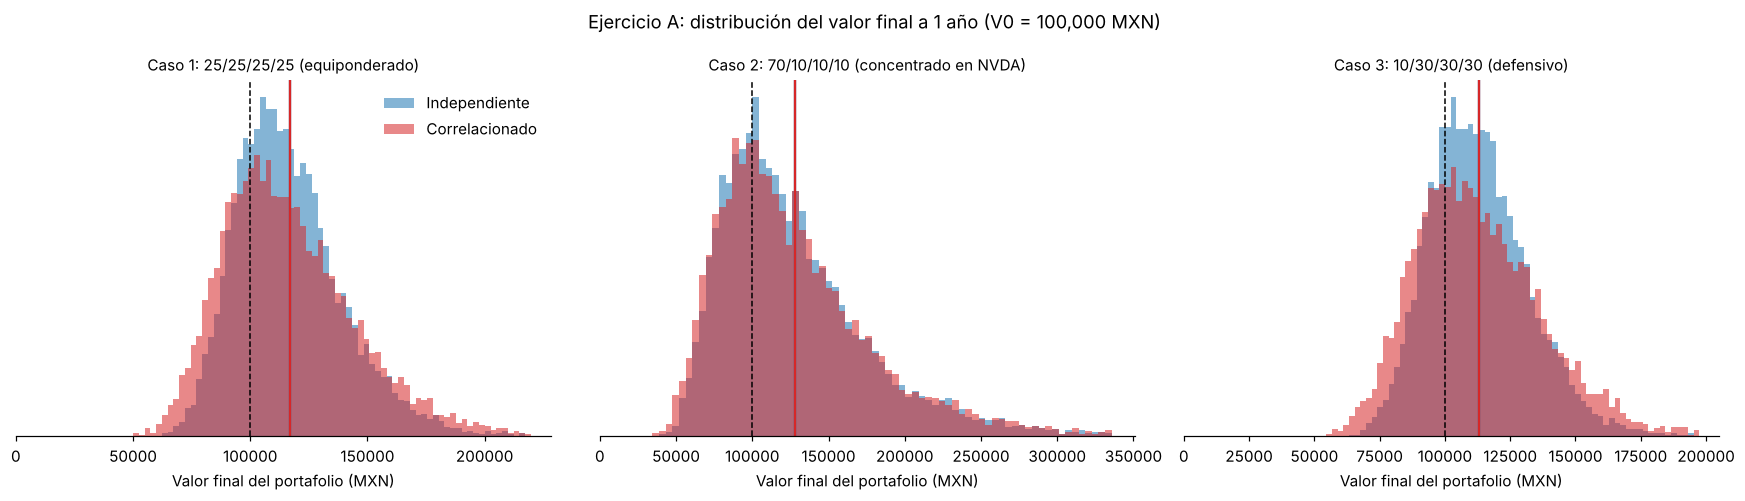

In [5]:
plot_hist(pathsA, labA, "Ejercicio A: distribución del valor final a 1 año (V0 = 100,000 MXN)")

**Qué observo:** las medias (líneas verticales) prácticamente coinciden. Lo que cambia es la **forma**: en los casos 1 y 3 el histograma rojo (correlacionado) es más ancho, con cola izquierda más larga (más escenarios con pérdidas fuertes) y cola derecha más larga. En el caso 2 (70% NVDA) casi no hay diferencia, porque el riesgo ya está dominado por un solo activo.

### Paso 1.4: Evolución en el año

La línea es la media y la banda cubre los percentiles 5 a 95 de las trayectorias.

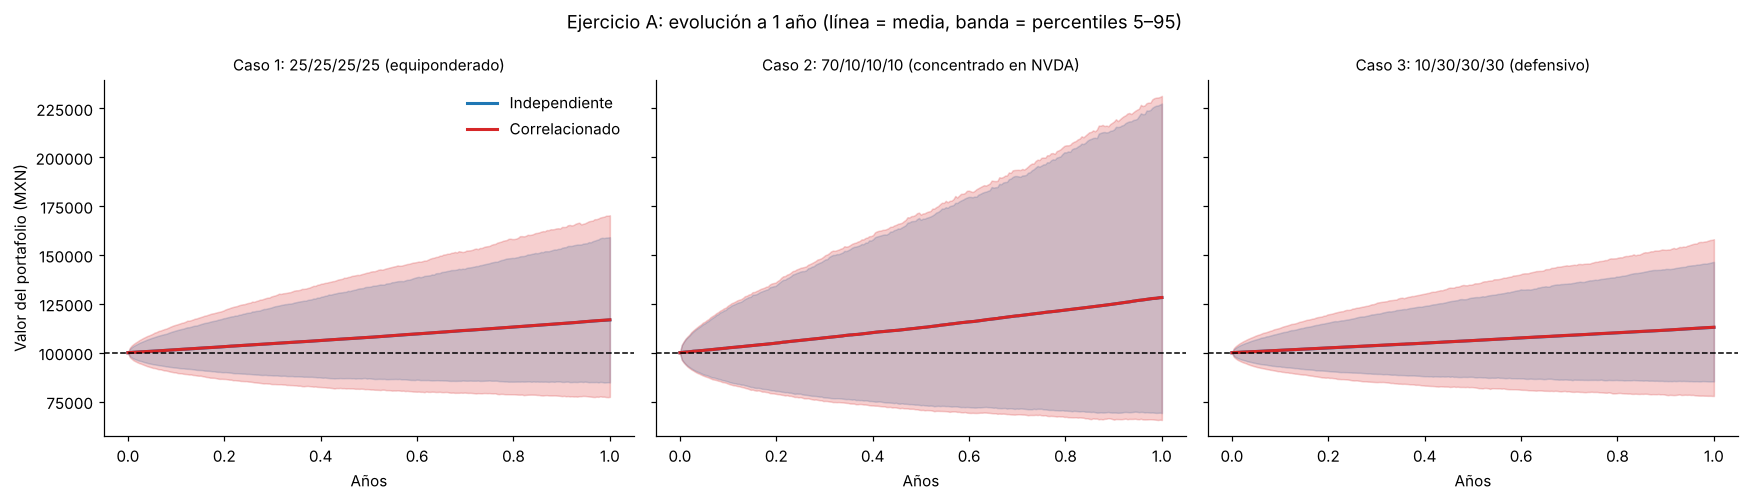

In [6]:
plot_evol(pathsA, labA, "Ejercicio A: evolución a 1 año (línea = media, banda = percentiles 5–95)")

**Qué observo:** las trayectorias medias son indistinguibles, pero la banda correlacionada (roja) se abre más rápido y termina más ancha en los esquemas 1 y 3. La correlación ensancha el rango de resultados sin cambiar el promedio.

### Paso 1.5: Tabla de métricas de riesgo

In [7]:
display(formato(dfA))

Media Desv. est.      P5  Mediana      P95 P(pérdida) VaR 95% CVaR 95%
Esquema                              Caso                                                                                    
1: 25/25/25/25 (equiponderado)       Independiente   116,775     23,378  84,791  113,686  159,093      24.7%  15,209   20,814
                                     Correlacionado  116,831     29,289  77,354  112,611  170,320      31.0%  22,646   29,259
2: 70/10/10/10 (concentrado en NVDA) Independiente   128,218     51,412  69,095  116,743  227,518      32.8%  30,905   38,267
                                     Correlacionado  128,240     53,707  65,561  116,602  231,451      34.2%  34,439   42,419
3: 10/30/30/30 (defensivo)           Independiente   112,961     19,056  85,281  111,171  146,483      26.2%  14,719   20,175
                                     Correlacionado  113,028     24,900  77,841  109,971  158,075      33.1%  22,159   28,403

**Qué observo (ejercicio A):**

1. **La media casi no cambia** (~0.05%): la correlación no altera el rendimiento esperado.
2. **La desviación estándar sube** ~25% en el esquema 1 (23.4 mil → 29.3 mil) y ~31% en el esquema 3 (19.1 mil → 24.9 mil).
3. **El riesgo de pérdida se subestima bajo independencia:** en el esquema 1 el VaR 95% pasa de ~15 mil a ~23 mil MXN (+49%) y la probabilidad de perder dinero de 24.7% a 31.0%.
4. **El esquema concentrado casi no cambia** (VaR 30.9 mil → 34.4 mil): la correlación importa más cuanto **más diversificado** está el portafolio, porque la diversificación es justo lo que la independencia sobrestima.
5. Aun con activos de sectores distintos, suponer independencia no es inocuo.

---
## 2. Ejercicio B: AAPL, MSFT, NVDA

### Paso 2.1: Parámetros y matriz de correlación

Ahora son tres tecnológicas de gran capitalización, así que la correlación es **alta** (0.60 a 0.70). Los esquemas son los pedidos: `[1, 0, 0]`, `[0.33, 0.33, 0.34]` y `[0.2, 0.2, 0.6]`. En el caso "correlacionado" usamos Cholesky, como en la clase del ejercicio B.

In [8]:
namesB = ["AAPL", "MSFT", "NVDA"]
muB  = [0.18, 0.20, 0.30]
sigB = [0.30, 0.28, 0.50]
RB = corr_from_upper(3, [0.70, 0.60, 0.65])   # AAPL-MSFT, AAPL-NVDA, MSFT-NVDA
schB = [[1, 0, 0], [0.33, 0.33, 0.34], [0.2, 0.2, 0.6]]
labB = ["[1, 0, 0] (100% AAPL)", "[0.33, 0.33, 0.34]", "[0.2, 0.2, 0.6] (60% NVDA)"]

print("Eigenvalores de R:", np.linalg.eigvalsh(RB).round(3))
display(pd.DataFrame(RB, index=namesB, columns=namesB).round(2))

dfB, pathsB, eiB, ecB = run_exercise(muB, sigB, RB, schB, labB)
print("Máx. |corr empírica - objetivo|  independiente:", np.abs(eiB - np.eye(3)).max().round(4),
      "| correlacionado:", np.abs(ecB - RB).max().round(4))

Eigenvalores de R: [0.292 0.407 2.301]
Máx. |corr empírica - objetivo|  independiente: 0.0008 | correlacionado: 0.0004


,AAPL,MSFT,NVDA
AAPL,1.0,0.70,0.60
MSFT,0.7,1.00,0.65
NVDA,0.6,0.65,1.00


### Paso 2.2: Distribución del valor final

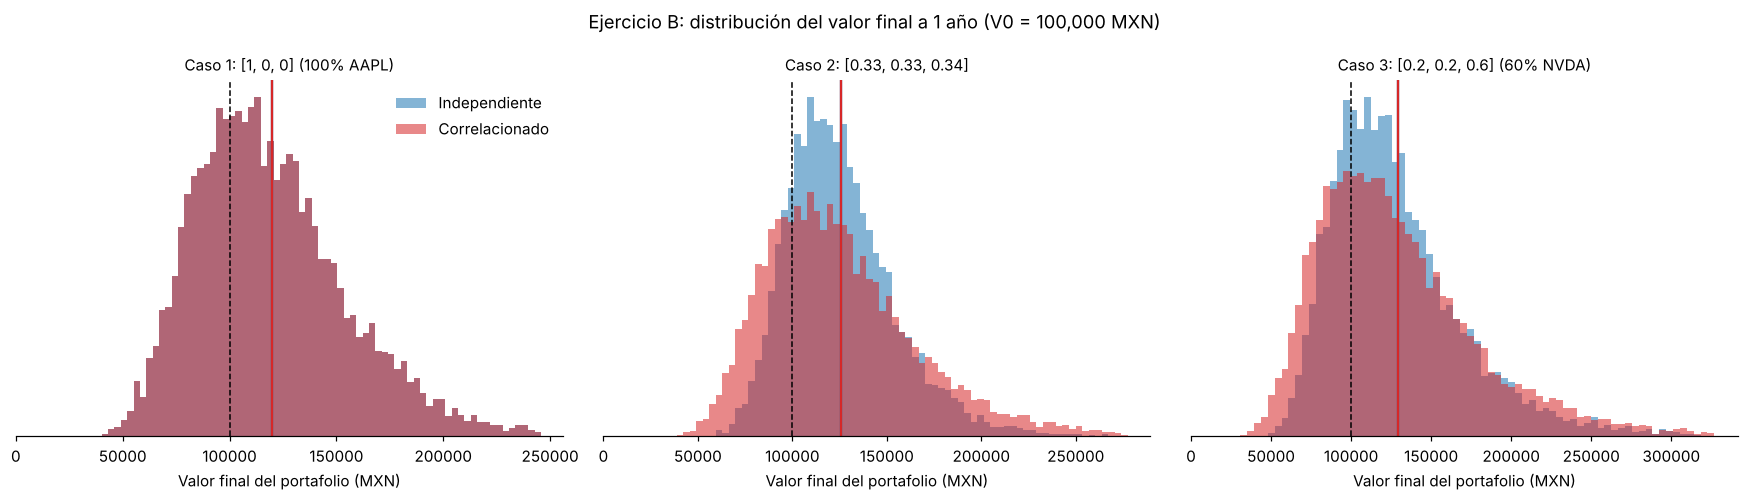

In [9]:
plot_hist(pathsB, labB, "Ejercicio B: distribución del valor final a 1 año (V0 = 100,000 MXN)")

**Qué observo:** en `[1, 0, 0]` los dos histogramas coinciden exactamente (con un solo activo no hay nada que correlacionar; es el control del experimento). En `[0.33, 0.33, 0.34]` la diferencia es enorme: el histograma rojo es mucho más ancho. En `[0.2, 0.2, 0.6]` también se ensancha, aunque menos en términos relativos porque domina NVDA.

### Paso 2.3: Evolución en el año

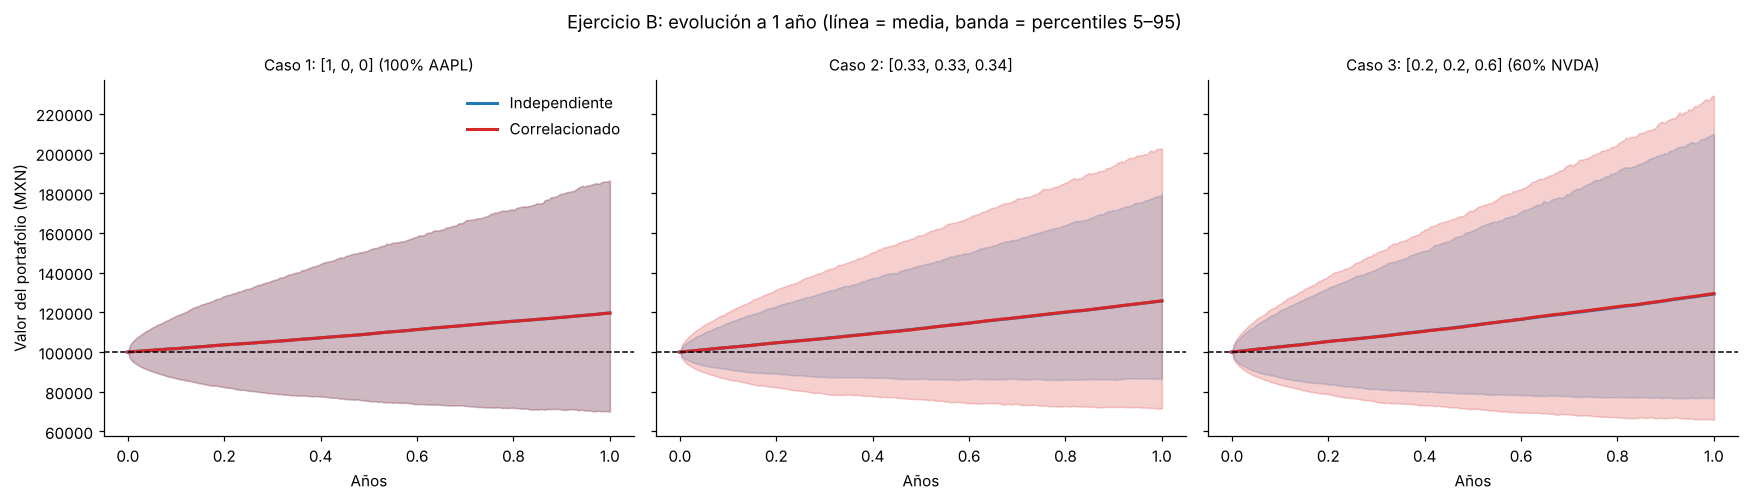

In [10]:
plot_evol(pathsB, labB, "Ejercicio B: evolución a 1 año (línea = media, banda = percentiles 5–95)")

**Qué observo:** las medias son indistinguibles, pero con correlación la banda 5–95 es visiblemente más ancha **desde los primeros meses**, y se abre más con el tiempo. En `[1, 0, 0]` las bandas se superponen por completo.

### Paso 2.4: Tabla de métricas de riesgo

In [11]:
display(formato(dfB))

Media Desv. est.      P5  Mediana      P95 P(pérdida) VaR 95% CVaR 95%
Esquema                       Caso                                                                                    
1: [1, 0, 0] (100% AAPL)      Independiente   119,642     36,368  69,986  114,183  186,325      32.8%  30,014   37,759
                              Correlacionado  119,642     36,368  69,986  114,183  186,325      32.8%  30,014   37,759
2: [0.33, 0.33, 0.34]         Independiente   125,696     29,218  86,632  121,666  179,367      17.7%  13,368   20,725
                              Correlacionado  125,771     41,519  71,481  119,397  202,533      29.2%  28,519   36,660
3: [0.2, 0.2, 0.6] (60% NVDA) Independiente   129,188     43,614  76,960  120,810  209,863      26.0%  23,040   30,533
                              Correlacionado  129,404     52,102  65,767  119,429  228,896      32.0%  34,233   43,060

**Qué observo (ejercicio B):**

1. **`[1, 0, 0]` es idéntico en ambos casos**, como debe ser.
2. **El portafolio equiponderado es donde más se nota:** la desviación estándar sube 42% (29.2 mil → 41.5 mil), el VaR 95% se **duplica** (13.4 mil → 28.5 mil) y la probabilidad de pérdida pasa de 17.7% a 29.2%. Bajo independencia el portafolio parecía mucho más seguro de lo que realmente es.
3. **Con correlaciones altas, diversificar entre tecnológicas ayuda poco:** el portafolio equiponderado correlacionado tiene un riesgo casi igual al de tener todo en AAPL (σ teórica 31.7% vs 30.0%), aunque en el mundo independiente parecía ser ~28% menos riesgoso.
4. **Cargar 60% en NVDA** sube media y riesgo. Con correlación, el P5 baja a ~65.8 mil y el P95 sube a ~229 mil: más upside, pero un VaR ~48% mayor que bajo independencia.

---
## 3. Conclusiones

- **La correlación no cambia el rendimiento esperado, cambia el riesgo.** Ignorarla produce distribuciones demasiado angostas, colas demasiado delgadas y un VaR demasiado optimista.
- **El efecto crece con la diversificación y con la correlación:** moderado en el ejercicio A (ρ de 0.15 a 0.35) y fuerte en el B (ρ de 0.6 a 0.7).
- **"Sectores distintos" no equivale a "independientes".** La diversificación real depende de la correlación efectiva, no solo del número de activos.

### Limitaciones
- $\mu$, $\sigma$ y $\rho$ son **supuestos**, no estimados con datos históricos; con los de clase los números exactos cambiarán, pero el patrón cualitativo debería mantenerse.
- GBM supone retornos lognormales y correlación **constante**. En crisis las correlaciones suelen subir y las colas son más gordas, así que el riesgo real puede ser mayor.
- No se modela explícitamente el tipo de cambio USD/MXN ni GBP/MXN para los activos extranjeros.